In [ ]:
#  1: INSTALL LIBRARIES & IMPORT
#  Product Association & Bundling


# Install mlxtend for association rules
!pip install mlxtend -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print(" Libraries installed and imported successfully!")
print(f"Pandas version: {pd.__version__}")

 Libraries installed and imported successfully!
Pandas version: 2.2.3


In [ ]:
#  2: LOAD DATA & SEGMENTATION RESULTS

print("="*60)
print("LOADING DATA")
print("="*60)

# Upload segmentation_results.csv first
try:
    seg_df = pd.read_csv('segmentation_results.csv')
    print(" Segmentation results loaded from 'segmentation_results.csv'")
except FileNotFoundError:
    print(" Error: 'segmentation_results.csv' not found!")
    print("   Please upload the file using the Files panel (📁).")
    print("   Then run this cell again.")

# Load cleaned transaction data
try:
    transactions_df = pd.read_csv('online_retail_cleaned.csv')
    print(" Cleaned transaction data loaded from 'online_retail_cleaned.csv'")
except FileNotFoundError:
    print(" Error: 'online_retail_cleaned.csv' not found!")
    print("   Please upload the file using the Files panel (📁).")

print(f"\n Segmentation Data Shape: {seg_df.shape}")
print(f" Transaction Data Shape: {transactions_df.shape}")

# Show segment distribution
print("\n Segment Distribution:")
print(seg_df['Final_Cluster'].value_counts().sort_index())

# Show segment labels if available
if 'Segment_Label' in seg_df.columns:
    print("\n Segment Labels:")
    print(seg_df[['Final_Cluster', 'Segment_Label']].drop_duplicates().sort_values('Final_Cluster'))

display(seg_df.head())
display(transactions_df.head())

LOADING DATA
 Segmentation results loaded from 'segmentation_results.csv'
 Cleaned transaction data loaded from 'online_retail_cleaned.csv'

 Segmentation Data Shape: (3614, 14)
 Transaction Data Shape: (339422, 9)

 Segment Distribution:
Final_Cluster
0     847
1     877
2    1421
3     469
Name: count, dtype: int64

 Segment Labels:
   Final_Cluster              Segment_Label
8              0  Regular Average Customers
0              1          At-Risk Customers
1              2      New/Occasional Buyers
3              3  Regular Average Customers


,CustomerID,Recency,Frequency,Monetary,AvgOrderValue,TotalQuantity,Recency_Scaled,Frequency_Scaled,Monetary_Scaled,KMeans_Cluster,DBSCAN_Cluster,Hierarchical_Cluster,Final_Cluster,Segment_Label
0,12348.0,248,3,90.20,15.033333,140,1.708549,0.001907,-0.911484,1,0,0,1,At-Risk Customers
1,12349.0,18,1,999.15,17.226724,523,-0.798110,-0.859411,0.752173,2,0,2,2,New/Occasional Buyers
2,12350.0,309,1,294.40,18.400000,196,2.373359,-0.859411,-0.537736,1,0,0,1,At-Risk Customers
3,12352.0,35,8,1010.61,13.843973,437,-0.612835,2.155202,0.773148,3,0,1,3,Regular Average Customers
4,12353.0,203,1,29.30,14.650000,14,1.218116,-0.859411,-1.022950,1,0,0,1,At-Risk Customers


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [ ]:
#  3: PREPARE TRANSACTION DATA WITH SEGMENT LABELS

print("="*60)
print("PREPARING TRANSACTION DATA WITH SEGMENT LABELS")
print("="*60)

# Merge transaction data with segment information
# First, clean the transaction data to include only necessary columns
transaction_cols = ['InvoiceNo', 'StockCode', 'Description', 'CustomerID', 'Quantity', 'UnitPrice']
trans_df = transactions_df[transaction_cols].copy()

# Merge with segment data
merged_df = trans_df.merge(seg_df[['CustomerID', 'Final_Cluster', 'Segment_Label']],
                           on='CustomerID', how='inner')

print(f" Merged data shape: {merged_df.shape}")
print(f" Unique invoices: {merged_df['InvoiceNo'].nunique()}")
print(f" Unique customers: {merged_df['CustomerID'].nunique()}")

# Check segment distribution in transactions
print("\n Segment Distribution in Transactions:")
print(merged_df['Segment_Label'].value_counts())

# Create a column for product descriptions (clean them)
merged_df['Product'] = merged_df['Description'].str.strip().str.upper()

display(merged_df.head())

PREPARING TRANSACTION DATA WITH SEGMENT LABELS
 Merged data shape: (181086, 8)
 Unique invoices: 10826
 Unique customers: 3614

 Segment Distribution in Transactions:
Segment_Label
Regular Average Customers    121825
New/Occasional Buyers         40023
At-Risk Customers             19238
Name: count, dtype: int64


,InvoiceNo,StockCode,Description,CustomerID,Quantity,UnitPrice,Final_Cluster,Segment_Label,Product
0,536380,22961,JAM MAKING SET PRINTED,17809.0,24,1.45,0,Regular Average Customers,JAM MAKING SET PRINTED
1,536382,10002,INFLATABLE POLITICAL GLOBE,16098.0,12,0.85,3,Regular Average Customers,INFLATABLE POLITICAL GLOBE
2,536382,21912,VINTAGE SNAKES & LADDERS,16098.0,8,3.75,3,Regular Average Customers,VINTAGE SNAKES & LADDERS
3,536382,21832,CHOCOLATE CALCULATOR,16098.0,12,1.65,3,Regular Average Customers,CHOCOLATE CALCULATOR
4,536382,22411,JUMBO SHOPPER VINTAGE RED PAISLEY,16098.0,10,1.95,3,Regular Average Customers,JUMBO SHOPPER VINTAGE RED PAISLEY


In [ ]:
#  4: CREATE BASKET DATA FOR EACH SEGMENT

print("="*60)
print("CREATING BASKET DATA FOR EACH SEGMENT")
print("="*60)

# Function to create basket data for a specific segment
def create_basket_data(data, segment_label):
    """
    Create transaction basket data for a specific segment
    """
    # Filter data for this segment
    segment_data = data[data['Segment_Label'] == segment_label]

    # Group by InvoiceNo and create list of products
    basket = segment_data.groupby('InvoiceNo')['Product'].apply(list).reset_index()
    basket.columns = ['InvoiceNo', 'Products']

    # Add segment label
    basket['Segment'] = segment_label

    return basket

# Get unique segments
segments = merged_df['Segment_Label'].unique()
print(f" Found {len(segments)} segments:")
for seg in segments:
    print(f"   • {seg}")

# Create basket data for each segment
basket_data = {}
for seg in segments:
    basket_data[seg] = create_basket_data(merged_df, seg)
    print(f"\n {seg}:")
    print(f"   • Invoices: {len(basket_data[seg])}")
    print(f"   • Average products per transaction: {basket_data[seg]['Products'].apply(len).mean():.2f}")

# Show sample basket
sample_segment = segments[0]
print(f"\n Sample basket data for '{sample_segment}':")
display(basket_data[sample_segment].head())

CREATING BASKET DATA FOR EACH SEGMENT
 Found 3 segments:
   • Regular Average Customers
   • New/Occasional Buyers
   • At-Risk Customers

 Regular Average Customers:
   • Invoices: 7069
   • Average products per transaction: 17.23

 New/Occasional Buyers:
   • Invoices: 2368
   • Average products per transaction: 16.90

 At-Risk Customers:
   • Invoices: 1389
   • Average products per transaction: 13.85

 Sample basket data for 'Regular Average Customers':


,InvoiceNo,Products,Segment
0,536380,[JAM MAKING SET PRINTED],Regular Average Customers
1,536382,"[INFLATABLE POLITICAL GLOBE, VINTAGE SNAKES & ...",Regular Average Customers
2,536397,[SET OF 3 BLACK FLYING DUCKS],Regular Average Customers
3,536401,"[BIRD HOUSE HOT WATER BOTTLE, BOUDOIR SQUARE T...",Regular Average Customers
4,536404,"[HEART IVORY TRELLIS SMALL, CLEAR DRAWER KNOB ...",Regular Average Customers


In [ ]:
#  5: APPLY ASSOCIATION RULE MINING (APRIORI)

print("="*60)
print("APPLYING ASSOCIATION RULE MINING")
print("="*60)

from mlxtend.preprocessing import TransactionEncoder

# Function to get association rules for a segment
def get_association_rules(basket_df, min_support=0.01, min_confidence=0.2, min_lift=1.0):
    """
    Get association rules for a basket dataset
    """
    # Convert to list of transactions
    transactions = basket_df['Products'].tolist()

    # Encode transactions
    te = TransactionEncoder()
    te_ary = te.fit(transactions).transform(transactions)
    df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

    # Apply Apriori
    frequent_itemsets = apriori(df_encoded, min_support=min_support, use_colnames=True)

    # Generate association rules
    rules = association_rules(frequent_itemsets, metric="lift", min_threshold=min_lift)

    # Filter by confidence
    rules = rules[rules['confidence'] >= min_confidence]

    # Sort by lift
    rules = rules.sort_values('lift', ascending=False)

    return rules, frequent_itemsets

# Parameters
min_support = 0.01  # Minimum support (1% of transactions)
min_confidence = 0.2  # Minimum confidence (20%)
min_lift = 1.0  # Minimum lift (>1 indicates meaningful association)

print(" Parameters:")
print(f"   min_support: {min_support}")
print(f"   min_confidence: {min_confidence}")
print(f"   min_lift: {min_lift}")

# Get rules for each segment
rules_dict = {}
itemsets_dict = {}

for seg in segments:
    print(f"\n Processing '{seg}'...")
    basket_df = basket_data[seg]

    if len(basket_df) > 10:  # Only process if enough transactions
        try:
            rules, itemsets = get_association_rules(basket_df, min_support, min_confidence, min_lift)
            rules_dict[seg] = rules
            itemsets_dict[seg] = itemsets
            print(f"    {len(rules)} rules found")
        except Exception as e:
            print(f"    Error: {str(e)}")
            rules_dict[seg] = pd.DataFrame()
            itemsets_dict[seg] = pd.DataFrame()
    else:
        print(f"    Too few transactions ({len(basket_df)}). Skipping...")
        rules_dict[seg] = pd.DataFrame()
        itemsets_dict[seg] = pd.DataFrame()

# Display summary
print("\n Summary of Rules Found:")
for seg in segments:
    print(f"   • {seg}: {len(rules_dict[seg])} rules")

APPLYING ASSOCIATION RULE MINING
 Parameters:
   min_support: 0.01
   min_confidence: 0.2
   min_lift: 1.0

 Processing 'Regular Average Customers'...
    356 rules found

 Processing 'New/Occasional Buyers'...
    230 rules found

 Processing 'At-Risk Customers'...
    175 rules found

 Summary of Rules Found:
   • Regular Average Customers: 356 rules
   • New/Occasional Buyers: 230 rules
   • At-Risk Customers: 175 rules


In [ ]:
#  6: DISPLAY TOP RULES FOR EACH SEGMENT

print("="*60)
print("TOP RULES FOR EACH SEGMENT")
print("="*60)

def display_top_rules(rules, segment_name, top_n=5):
    """
    Display top N rules for a segment
    """
    if len(rules) == 0:
        print(f"\n {segment_name}: No rules found.")
        return

    print(f"\n {segment_name} - Top {top_n} Rules (by Lift):")

    # Format antecedents and consequents
    rules_display = rules.head(top_n).copy()
    rules_display['antecedents'] = rules_display['antecedents'].apply(lambda x: ', '.join(list(x)))
    rules_display['consequents'] = rules_display['consequents'].apply(lambda x: ', '.join(list(x)))

    # Select columns to display
    display_cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
    display(rules_display[display_cols])

    # Also show top rules by confidence
    print(f"\n {segment_name} - Top {top_n} Rules (by Confidence):")
    rules_by_conf = rules.sort_values('confidence', ascending=False).head(top_n)
    rules_by_conf_display = rules_by_conf.copy()
    rules_by_conf_display['antecedents'] = rules_by_conf_display['antecedents'].apply(lambda x: ', '.join(list(x)))
    rules_by_conf_display['consequents'] = rules_by_conf_display['consequents'].apply(lambda x: ', '.join(list(x)))
    display(rules_by_conf_display[display_cols])

# Display top rules for each segment
for seg in segments:
    if seg in rules_dict:
        display_top_rules(rules_dict[seg], seg, top_n=5)

TOP RULES FOR EACH SEGMENT

 Regular Average Customers - Top 5 Rules (by Lift):


,antecedents,consequents,support,confidence,lift
262,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,0.010893,0.827957,56.823572
263,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE BEDROOM,0.010893,0.747573,56.823572
269,REGENCY SUGAR BOWL GREEN,REGENCY MILK JUG PINK,0.010185,0.774194,52.121659
268,REGENCY MILK JUG PINK,REGENCY SUGAR BOWL GREEN,0.010185,0.685714,52.121659
283,SET OF 3 WOODEN STOCKING DECORATION,SET OF 3 WOODEN TREE DECORATIONS,0.010751,0.690909,48.356796



 Regular Average Customers - Top 5 Rules (by Confidence):


,antecedents,consequents,support,confidence,lift
314,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.017541,0.873239,25.828157
304,"ALARM CLOCK BAKELIKE RED, ALARM CLOCK BAKELIKE...",ALARM CLOCK BAKELIKE GREEN,0.010327,0.848837,23.167684
303,"ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELI...",ALARM CLOCK BAKELIKE RED,0.010327,0.839080,19.971245
315,"PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.017541,0.837838,21.854892
262,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,0.010893,0.827957,56.823572



 New/Occasional Buyers - Top 5 Rules (by Lift):


...

,antecedents,consequents,support,confidence,lift
194,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.013091,0.939394,35.878788
231,"WOODEN TREE CHRISTMAS SCANDINAVIAN, WOODEN HEA...",WOODEN STAR CHRISTMAS SCANDINAVIAN,0.017314,0.911111,21.575111
40,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.018581,0.897959,34.296248
10,BLUE HAPPY BIRTHDAY BUNTING,PINK HAPPY BIRTHDAY BUNTING,0.010980,0.896552,55.869328
226,"SET OF 12 MINI LOAF BAKING CASES, SET OF 6 TEA...",SET OF 6 SNACK LOAF BAKING CASES,0.012669,0.857143,32.737327



 At-Risk Customers - Top 5 Rules (by Lift):


,antecedents,consequents,support,confidence,lift
158,RED RETROSPOT CUP,RED RETROSPOT PLATE,0.011519,0.888889,64.982456
159,RED RETROSPOT PLATE,RED RETROSPOT CUP,0.011519,0.842105,64.982456
41,CHILDS GARDEN FORK BLUE,CHILDS GARDEN FORK PINK,0.010079,0.736842,60.204334
40,CHILDS GARDEN FORK PINK,CHILDS GARDEN FORK BLUE,0.010079,0.823529,60.204334
30,BLUE POLKADOT BOWL,PINK POLKADOT BOWL,0.010799,0.750000,57.875000



 At-Risk Customers - Top 5 Rules (by Confidence):


,antecedents,consequents,support,confidence,lift
173,"RED HANGING HEART T-LIGHT HOLDER, CANDLEHOLDER...",WHITE HANGING HEART T-LIGHT HOLDER,0.010799,0.937500,9.170335
140,POPPY'S PLAYHOUSE BATHROOM,POPPY'S PLAYHOUSE KITCHEN,0.010079,0.933333,46.300000
143,POPPY'S PLAYHOUSE BATHROOM,POPPY'S PLAYHOUSE LIVINGROOM,0.010079,0.933333,51.856000
192,"POPPY'S PLAYHOUSE LIVINGROOM, POPPY'S PLAYHOUS...",POPPY'S PLAYHOUSE BEDROOM,0.012959,0.900000,43.106897
158,RED RETROSPOT CUP,RED RETROSPOT PLATE,0.011519,0.888889,64.982456


In [ ]:
#  7: CREATE BUNDLE RECOMMENDATIONS

print("="*60)
print("CREATING BUNDLE RECOMMENDATIONS")
print("="*60)

# Function to create bundle recommendations from rules
def create_bundle_recommendations(rules, segment_name, top_n=5):
    """
    Create bundle recommendations from association rules
    """
    if len(rules) == 0:
        return pd.DataFrame()

    # Take top rules by lift
    top_rules = rules.head(top_n).copy()

    # Format antecedents and consequents
    bundles = []
    for idx, rule in top_rules.iterrows():
        antecedents = ', '.join(list(rule['antecedents']))
        consequents = ', '.join(list(rule['consequents']))
        bundles.append({
            'Segment': segment_name,
            'Bundle Products': f"{antecedents} + {consequents}",
            'Antecedents': antecedents,
            'Consequents': consequents,
            'Support': round(rule['support'], 4),
            'Confidence': round(rule['confidence'], 4),
            'Lift': round(rule['lift'], 4)
        })

    return pd.DataFrame(bundles)

# Create recommendations for each segment
all_recommendations = []

for seg in segments:
    if seg in rules_dict and len(rules_dict[seg]) > 0:
        recs = create_bundle_recommendations(rules_dict[seg], seg)
        all_recommendations.append(recs)

# Combine all recommendations
if all_recommendations:
    bundle_recommendations = pd.concat(all_recommendations, ignore_index=True)
else:
    bundle_recommendations = pd.DataFrame()

print(f" Bundle Recommendations Created: {len(bundle_recommendations)}")

if len(bundle_recommendations) > 0:
    print("\n Sample Bundle Recommendations:")
    display(bundle_recommendations.head(10))
else:
    print(" No bundle recommendations generated. Try adjusting min_support or min_confidence.")

CREATING BUNDLE RECOMMENDATIONS
 Bundle Recommendations Created: 15

 Sample Bundle Recommendations:


,Segment,Bundle Products,Antecedents,Consequents,Support,Confidence,Lift
0,Regular Average Customers,POPPY'S PLAYHOUSE BEDROOM + POPPY'S PLAYHOUSE ...,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,0.0109,0.8280,56.8236
1,Regular Average Customers,POPPY'S PLAYHOUSE KITCHEN + POPPY'S PLAYHOUSE ...,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE BEDROOM,0.0109,0.7476,56.8236
2,Regular Average Customers,REGENCY SUGAR BOWL GREEN + REGENCY MILK JUG PINK,REGENCY SUGAR BOWL GREEN,REGENCY MILK JUG PINK,0.0102,0.7742,52.1217
3,Regular Average Customers,REGENCY MILK JUG PINK + REGENCY SUGAR BOWL GREEN,REGENCY MILK JUG PINK,REGENCY SUGAR BOWL GREEN,0.0102,0.6857,52.1217
4,Regular Average Customers,SET OF 3 WOODEN STOCKING DECORATION + SET OF 3...,SET OF 3 WOODEN STOCKING DECORATION,SET OF 3 WOODEN TREE DECORATIONS,0.0108,0.6909,48.3568
5,New/Occasional Buyers,PINK HAPPY BIRTHDAY BUNTING + BLUE HAPPY BIRTH...,PINK HAPPY BIRTHDAY BUNTING,BLUE HAPPY BIRTHDAY BUNTING,0.0110,0.6842,55.8693
6,New/Occasional Buyers,BLUE HAPPY BIRTHDAY BUNTING + PINK HAPPY BIRTH...,BLUE HAPPY BIRTHDAY BUNTING,PINK HAPPY BIRTHDAY BUNTING,0.0110,0.8966,55.8693
7,New/Occasional Buyers,CHILDRENS CUTLERY SPACEBOY + CHILDRENS CUTLERY...,CHILDRENS CUTLERY SPACEBOY,CHILDRENS CUTLERY DOLLY GIRL,0.0106,0.6579,47.2089
8,New/Occasional Buyers,CHILDRENS CUTLERY DOLLY GIRL + CHILDRENS CUTLE...,CHILDRENS CUTLERY DOLLY GIRL,CHILDRENS CUTLERY SPACEBOY,0.0106,0.7576,47.2089
9,New/Occasional Buyers,POPPY'S PLAYHOUSE KITCHEN + POPPY'S PLAYHOUSE ...,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE BEDROOM,0.0118,0.6512,44.0558


VISUALIZING ASSOCIATION RULES


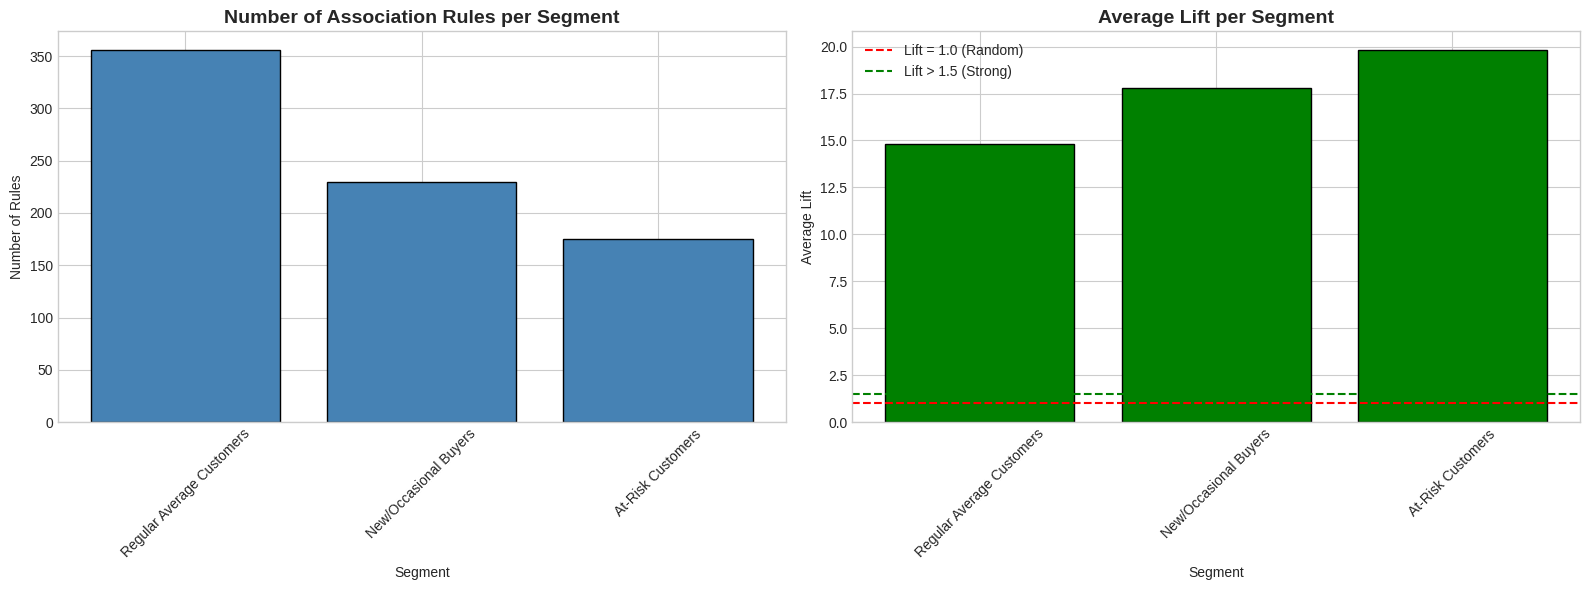

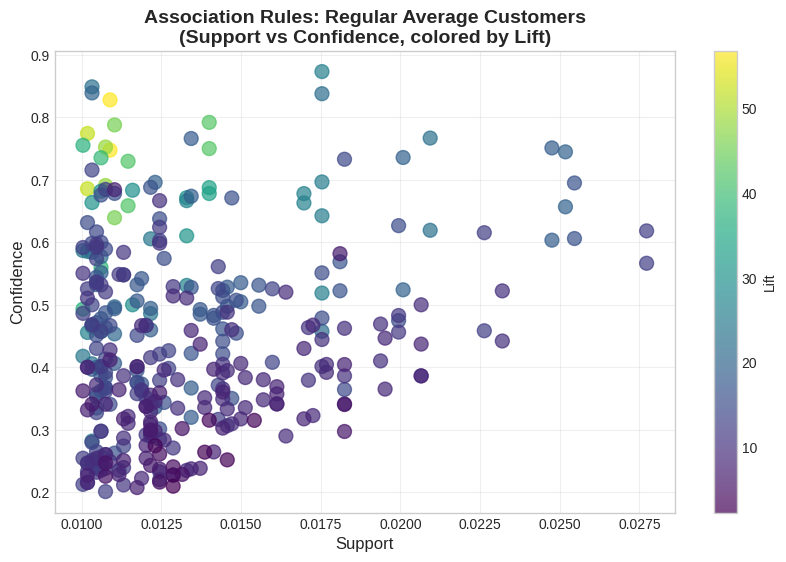

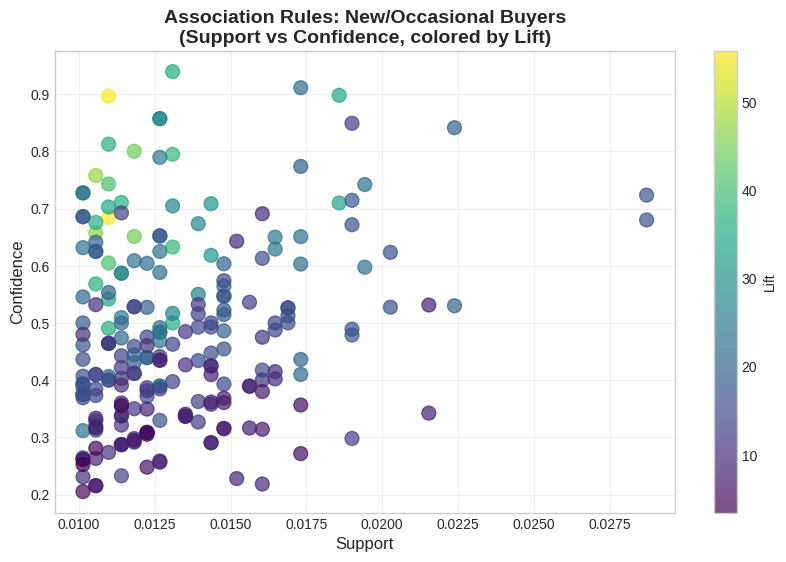

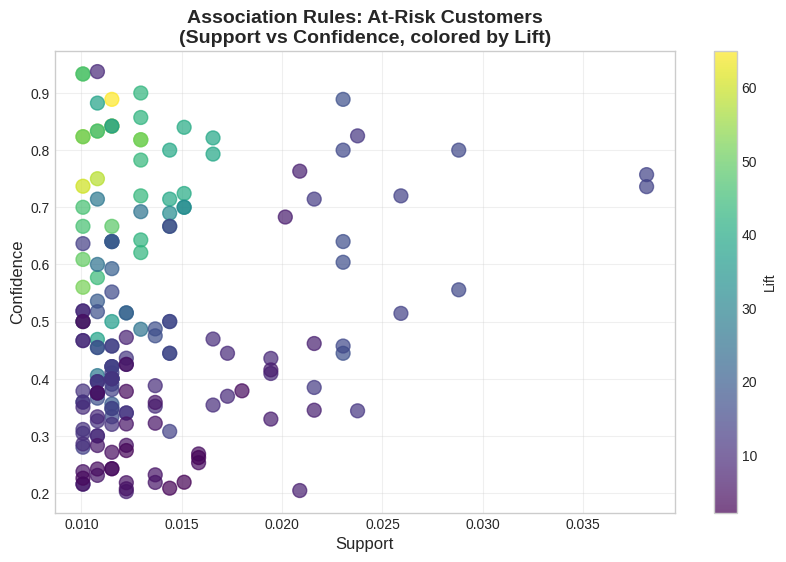

In [9]:
print("="*60)
print("VISUALIZING ASSOCIATION RULES")
print("="*60)

# Create visualization for each segment with rules
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Number of rules per segment
segment_names = []
rule_counts = []
for seg in segments:
    if seg in rules_dict:
        segment_names.append(seg)
        rule_counts.append(len(rules_dict[seg]))

if segment_names:
    axes[0].bar(segment_names, rule_counts, color='steelblue', edgecolor='black')
    axes[0].set_title('Number of Association Rules per Segment', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Segment')
    axes[0].set_ylabel('Number of Rules')
    axes[0].tick_params(axis='x', rotation=45)

# Plot 2: Average Lift per segment
avg_lift = []
for seg in segments:
    if seg in rules_dict and len(rules_dict[seg]) > 0:
        avg_lift.append(rules_dict[seg]['lift'].mean())
    else:
        avg_lift.append(0)

if segment_names:
    colors = ['green' if x > 1.5 else 'orange' if x > 1.0 else 'red' for x in avg_lift]
    axes[1].bar(segment_names, avg_lift, color=colors, edgecolor='black')
    axes[1].axhline(y=1.0, color='red', linestyle='--', label='Lift = 1.0 (Random)')
    axes[1].axhline(y=1.5, color='green', linestyle='--', label='Lift > 1.5 (Strong)')
    axes[1].set_title('Average Lift per Segment', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Segment')
    axes[1].set_ylabel('Average Lift')
    axes[1].legend()
    axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('rules_summary.png', dpi=300, bbox_inches='tight')
plt.show()

# If there are rules, create a scatter plot
for seg in segments:
    if seg in rules_dict and len(rules_dict[seg]) > 0:
        rules = rules_dict[seg]
        plt.figure(figsize=(10, 6))
        scatter = plt.scatter(rules['support'], rules['confidence'],
                             c=rules['lift'], cmap='viridis', s=100, alpha=0.7)
        plt.colorbar(scatter, label='Lift')
        plt.xlabel('Support', fontsize=12)
        plt.ylabel('Confidence', fontsize=12)
        plt.title(f'Association Rules: {seg}\n(Support vs Confidence, colored by Lift)',
                 fontsize=14, fontweight='bold')
        plt.grid(True, alpha=0.3)
        # Replace '/' with '_' in the segment name for the filename
        cleaned_seg_name = seg.replace('/', '_')
        plt.savefig(f'rule_scatter_{cleaned_seg_name.replace(" ", "_")}.png', dpi=300, bbox_inches='tight')
        plt.show()

In [ ]:
#  9: SEGMENT-SPECIFIC BUNDLE RECOMMENDATIONS

print("="*60)
print("SEGMENT-SPECIFIC BUNDLE RECOMMENDATIONS")
print("="*60)

# Create detailed recommendations for each segment
print("\n FINAL BUNDLE RECOMMENDATIONS BY SEGMENT:")
print("="*60)

for seg in segments:
    if seg in rules_dict and len(rules_dict[seg]) > 0:
        print(f"\n  {seg}")
        print("-" * 40)

        # Top 3 bundles by lift
        top_rules = rules_dict[seg].head(3)
        for idx, rule in top_rules.iterrows():
            antecedents = ', '.join(list(rule['antecedents']))
            consequents = ', '.join(list(rule['consequents']))
            print(f"   Bundle: {antecedents} → {consequents}")
            print(f"    Lift: {rule['lift']:.2f} | Confidence: {rule['confidence']:.2%} | Support: {rule['support']:.2%}")
            print()
    else:
        print(f"\n  {seg}")
        print("-" * 40)
        print("    No strong association rules found for this segment.")
        print("   (Try adjusting min_support or min_confidence parameters)")

# Create final recommendation table
if len(bundle_recommendations) > 0:
    print("\n Final Bundle Recommendations Table:")
    display(bundle_recommendations)

SEGMENT-SPECIFIC BUNDLE RECOMMENDATIONS

 FINAL BUNDLE RECOMMENDATIONS BY SEGMENT:

  Regular Average Customers
----------------------------------------
   Bundle: POPPY'S PLAYHOUSE BEDROOM → POPPY'S PLAYHOUSE KITCHEN
    Lift: 56.82 | Confidence: 82.80% | Support: 1.09%

   Bundle: POPPY'S PLAYHOUSE KITCHEN → POPPY'S PLAYHOUSE BEDROOM
    Lift: 56.82 | Confidence: 74.76% | Support: 1.09%

   Bundle: REGENCY SUGAR BOWL GREEN → REGENCY MILK JUG PINK
    Lift: 52.12 | Confidence: 77.42% | Support: 1.02%


  New/Occasional Buyers
----------------------------------------
   Bundle: PINK HAPPY BIRTHDAY BUNTING → BLUE HAPPY BIRTHDAY BUNTING
    Lift: 55.87 | Confidence: 68.42% | Support: 1.10%

   Bundle: BLUE HAPPY BIRTHDAY BUNTING → PINK HAPPY BIRTHDAY BUNTING
    Lift: 55.87 | Confidence: 89.66% | Support: 1.10%

   Bundle: CHILDRENS CUTLERY SPACEBOY → CHILDRENS CUTLERY DOLLY GIRL
    Lift: 47.21 | Confidence: 65.79% | Support: 1.06%


  At-Risk Customers
---------------------------------

,Segment,Bundle Products,Antecedents,Consequents,Support,Confidence,Lift
0,Regular Average Customers,POPPY'S PLAYHOUSE BEDROOM + POPPY'S PLAYHOUSE ...,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,0.0109,0.8280,56.8236
1,Regular Average Customers,POPPY'S PLAYHOUSE KITCHEN + POPPY'S PLAYHOUSE ...,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE BEDROOM,0.0109,0.7476,56.8236
2,Regular Average Customers,REGENCY SUGAR BOWL GREEN + REGENCY MILK JUG PINK,REGENCY SUGAR BOWL GREEN,REGENCY MILK JUG PINK,0.0102,0.7742,52.1217
3,Regular Average Customers,REGENCY MILK JUG PINK + REGENCY SUGAR BOWL GREEN,REGENCY MILK JUG PINK,REGENCY SUGAR BOWL GREEN,0.0102,0.6857,52.1217
4,Regular Average Customers,SET OF 3 WOODEN STOCKING DECORATION + SET OF 3...,SET OF 3 WOODEN STOCKING DECORATION,SET OF 3 WOODEN TREE DECORATIONS,0.0108,0.6909,48.3568
5,New/Occasional Buyers,PINK HAPPY BIRTHDAY BUNTING + BLUE HAPPY BIRTH...,PINK HAPPY BIRTHDAY BUNTING,BLUE HAPPY BIRTHDAY BUNTING,0.0110,0.6842,55.8693
6,New/Occasional Buyers,BLUE HAPPY BIRTHDAY BUNTING + PINK HAPPY BIRTH...,BLUE HAPPY BIRTHDAY BUNTING,PINK HAPPY BIRTHDAY BUNTING,0.0110,0.8966,55.8693
7,New/Occasional Buyers,CHILDRENS CUTLERY SPACEBOY + CHILDRENS CUTLERY...,CHILDRENS CUTLERY SPACEBOY,CHILDRENS CUTLERY DOLLY GIRL,0.0106,0.6579,47.2089
8,New/Occasional Buyers,CHILDRENS CUTLERY DOLLY GIRL + CHILDRENS CUTLE...,CHILDRENS CUTLERY DOLLY GIRL,CHILDRENS CUTLERY SPACEBOY,0.0106,0.7576,47.2089
9,New/Occasional Buyers,POPPY'S PLAYHOUSE KITCHEN + POPPY'S PLAYHOUSE ...,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE BEDROOM,0.0118,0.6512,44.0558


In [ ]:
#  CELL 10: SAVE RESULTS

print("="*60)
print("SAVING RESULTS")
print("="*60)

import os

# Save rules for each segment
for seg in segments:
    if seg in rules_dict and len(rules_dict[seg]) > 0:
        filename = f'association_rules_{seg.replace(" ", "_").replace("/", "_")}.csv'
        rules_dict[seg].to_csv(filename, index=False)
        print(f" Saved rules for '{seg}': {filename}")

# Save bundle recommendations
if len(bundle_recommendations) > 0:
    bundle_recommendations.to_csv('bundle_recommendations.csv', index=False)
    print(f" Bundle recommendations saved: bundle_recommendations.csv")

# Save summary of rules
summary_data = []
for seg in segments:
    if seg in rules_dict:
        summary_data.append({
            'Segment': seg,
            'Number_of_Rules': len(rules_dict[seg]),
            'Avg_Lift': rules_dict[seg]['lift'].mean() if len(rules_dict[seg]) > 0 else 0,
            'Max_Lift': rules_dict[seg]['lift'].max() if len(rules_dict[seg]) > 0 else 0
        })
summary_df = pd.DataFrame(summary_data)
summary_df.to_csv('association_rules_summary.csv', index=False)
print(f" Summary saved: association_rules_summary.csv")

print("\n Summary of Rules:")
display(summary_df)

# Download files
from google.colab import files

print("\n Downloading files...")

# CSV files to download
csv_files = ['bundle_recommendations.csv', 'association_rules_summary.csv']
for seg in segments:
    filename = f'association_rules_{seg.replace(" ", "_").replace("/", "_")}.csv'
    if os.path.exists(filename):
        csv_files.append(filename)

for file in csv_files:
    if os.path.exists(file):
        files.download(file)
        print(f" Downloaded: {file}")

print("\n All files downloaded successfully!")

SAVING RESULTS
 Saved rules for 'Regular Average Customers': association_rules_Regular_Average_Customers.csv
 Saved rules for 'New/Occasional Buyers': association_rules_New_Occasional_Buyers.csv
 Saved rules for 'At-Risk Customers': association_rules_At-Risk_Customers.csv
 Bundle recommendations saved: bundle_recommendations.csv
 Summary saved: association_rules_summary.csv

 Summary of Rules:


,Segment,Number_of_Rules,Avg_Lift,Max_Lift
0,Regular Average Customers,356,14.818629,56.823572
1,New/Occasional Buyers,230,17.810895,55.869328
2,At-Risk Customers,175,19.821182,64.982456


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Downloaded: bundle_recommendations.csv


...

<IPython.core.display.Javascript object>

 Downloaded: association_rules_New_Occasional_Buyers.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Downloaded: association_rules_At-Risk_Customers.csv

 All files downloaded successfully!


In [ ]:
#  CELL 11: PHASE 4 SUMMARY

print("="*60)
print("PHASE 4: PRODUCT ASSOCIATION & BUNDLING COMPLETE!")
print("="*60)

print("""
 PHASE 4 COMPLETED SUCCESSFULLY!

 SUMMARY:
-----------
1. ASSOCIATION RULE MINING:
   • Used Apriori Algorithm
   • Applied to each customer segment separately
   • Found product bundles for each segment

2. KEY METRICS:
   • Support: How frequently products appear together
   • Confidence: How likely B is purchased when A is purchased
   • Lift: How much more likely B is purchased when A is purchased

3. BUNDLE RECOMMENDATIONS:
   • Created segment-specific product bundles
   • Recommended top rules for each segment

4. BUSINESS VALUE:
   • Cross-selling opportunities identified
   • Targeted promotions per segment
   • Product placement strategies

 FILES GENERATED:
-----------------
   • association_rules_{segment}.csv (per segment)
   • bundle_recommendations.csv
   • association_rules_summary.csv
   • rules_summary.png
   • rule_scatter_{segment}.png

 PROJECT COMPLETE!
-------------------
   ✓ Phase 1: EDA
   ✓ Phase 2: Preprocessing & RFM Engineering
   ✓ Phase 3: Customer Segmentation
   ✓ Phase 4: Product Association & Bundling

========================================
""")

print("\n ALL PHASES COMPLETE! Project Ready for Final Report!")

PHASE 4: PRODUCT ASSOCIATION & BUNDLING COMPLETE!

 PHASE 4 COMPLETED SUCCESSFULLY!

 SUMMARY:
-----------
1. ASSOCIATION RULE MINING:
   • Used Apriori Algorithm
   • Applied to each customer segment separately
   • Found product bundles for each segment

2. KEY METRICS:
   • Support: How frequently products appear together
   • Confidence: How likely B is purchased when A is purchased
   • Lift: How much more likely B is purchased when A is purchased

3. BUNDLE RECOMMENDATIONS:
   • Created segment-specific product bundles
   • Recommended top rules for each segment

4. BUSINESS VALUE:
   • Cross-selling opportunities identified
   • Targeted promotions per segment
   • Product placement strategies

 FILES GENERATED:
-----------------
   • association_rules_{segment}.csv (per segment)
   • bundle_recommendations.csv
   • association_rules_summary.csv
   • rules_summary.png
   • rule_scatter_{segment}.png

 PROJECT COMPLETE!
-------------------
   ✓ Phase 1: EDA
   ✓ Phase 2: Preproce